In [1]:
# Objective: Analyze customer purchasing behavior, sales trends, product performance, and customer retention to help an e-commerce company 
# improve revenue and customer satisfaction.

In [2]:
import numpy as np
import pandas as pd
df = pd.read_csv("IndianEcommerce.csv")
df.info()      #-- From this function got information about informations of columns
df.describe()  #-- From this function got summerized information of the Data count of columns, mean value of column, Standard Deviation, minimum value, 
               #   maximum value, 25% IQR, 50% IQR, 75% IQR.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30600 entries, 0 to 30599
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               30600 non-null  object 
 1   order_date             30600 non-null  object 
 2   state                  30600 non-null  object 
 3   zone                   30600 non-null  object 
 4   category               30582 non-null  object 
 5   brand_type             30600 non-null  object 
 6   customer_gender        30590 non-null  object 
 7   customer_age           30580 non-null  float64
 8   base_price             30600 non-null  float64
 9   discount_percent       30586 non-null  float64
 10  final_price            30588 non-null  float64
 11  units_sold             30600 non-null  int64  
 12  revenue                30600 non-null  float64
 13  sales_event            30600 non-null  object 
 14  competition_intensity  30600 non-null  object 
 15  in

,customer_age,base_price,discount_percent,final_price,units_sold,revenue
count,30580.000000,30600.000000,30586.000000,30588.000000,30600.000000,30600.000000
mean,35.570438,3898.637966,38.110964,2414.820728,31.705490,71046.176473
std,12.873400,3371.290126,16.609070,2264.924909,21.381121,83619.169649
min,18.000000,100.030000,0.010000,35.010000,2.000000,247.800000
25%,25.000000,1314.637500,24.840000,746.682500,16.000000,16682.002500
50%,33.000000,2975.015000,37.280000,1728.090000,27.000000,42125.910000
75%,45.000000,5342.480000,51.840000,3309.630000,42.000000,92568.725000
max,65.000000,14999.170000,65.000000,14682.280000,161.000000,906141.040000


In [3]:
df.head(51)    #-- from this function got top 50 data. 

,order_id,order_date,state,zone,category,brand_type,customer_gender,customer_age,base_price,discount_percent,final_price,units_sold,revenue,sales_event,competition_intensity,inventory_pressure
0,ORD0000001,2023-01-31,West Bengal,East,Fashion,Mass,Male,28.0,1810.89,65.00,633.81,29,18380.49,Normal,Medium,High
1,ORD0000002,2023-01-31,Gujarat,West,Sports & Fitness,Mass,Male,19.0,5678.15,50.83,2791.95,67,187060.65,Normal,Medium,High
2,ORD0000003,2023-01-31,Delhi NCR,North,Grocery Essentials,Mass,Male,25.0,169.98,35.26,110.05,57,6272.85,Normal,Medium,Low
3,ORD0000004,2023-01-31,Madhya Pradesh,Central,Footwear,Mass,Female,30.0,3244.91,61.94,1235.01,55,67925.55,Normal,High,High
4,ORD0000005,2023-01-31,Haryana,North,Fashion,Premium,Female,33.0,697.44,48.27,360.79,29,10462.91,Festival,Medium,High
5,ORD0000006,2023-01-31,Punjab,North,Grocery Essentials,Mass,Female,19.0,100.55,65.00,35.19,16,563.04,Festival,High,High
6,ORD0000007,2023-01-31,Delhi NCR,North,Home & Living,Mass,Female,47.0,2382.06,46.86,1265.83,34,43038.22,Normal,Medium,High
7,ORD0000008,2023-01-31,West Bengal,East,Fashion,Mass,Male,23.0,580.72,46.86,308.59,27,8331.93,Normal,Medium,High
8,ORD0000009,2023-01-31,West Bengal,East,Grocery Essentials,Mass,Male,45.0,132.67,65.00,46.43,52,2414.36,Festival,High,Low
9,ORD0000010,2023-01-31,Gujarat,West,Grocery Essentials,Premium,Male,40.0,419.25,40.48,249.54,44,10979.76,Normal,Medium,High


In [4]:
# DATA CLEANING --
# 1 - Missing values - 
df.isnull().sum() # -- from this got Total missing values in each column like there in (category - 18, customer_gender - 10, customer_age - 20, 
                  #    discount_percent - 14, final_price - 12).

order_id                  0
order_date                0
state                     0
zone                      0
category                 18
brand_type                0
customer_gender          10
customer_age             20
base_price                0
discount_percent         14
final_price              12
units_sold                0
revenue                   0
sales_event               0
competition_intensity     0
inventory_pressure        0
dtype: int64

In [5]:
(df.isnull().sum()/len(df))*100 # -- missing values in percentages.

order_id                 0.000000
order_date               0.000000
state                    0.000000
zone                     0.000000
category                 0.058824
brand_type               0.000000
customer_gender          0.032680
customer_age             0.065359
base_price               0.000000
discount_percent         0.045752
final_price              0.039216
units_sold               0.000000
revenue                  0.000000
sales_event              0.000000
competition_intensity    0.000000
inventory_pressure       0.000000
dtype: float64

In [6]:
df['customer_age'] = df['customer_age'].fillna(df['customer_age'].median())     # Remove missing by replacing with mean, median, mode.
df['category'] = df['category'].fillna(df['category'].mode()[0])
df['customer_gender'] = df['customer_gender'].fillna(df['customer_gender'].mode()[0])
df['discount_percent'] = df['discount_percent'].fillna(df['discount_percent'].mean())
df['final_price'] = df['final_price'].fillna(df['final_price'].mean())

In [7]:
df.isnull().sum()

order_id                 0
order_date               0
state                    0
zone                     0
category                 0
brand_type               0
customer_gender          0
customer_age             0
base_price               0
discount_percent         0
final_price              0
units_sold               0
revenue                  0
sales_event              0
competition_intensity    0
inventory_pressure       0
dtype: int64

In [8]:
df.duplicated().sum()  # There are no duplicate values in the Data.
df.drop_duplicates()

,order_id,order_date,state,zone,category,brand_type,customer_gender,customer_age,base_price,discount_percent,final_price,units_sold,revenue,sales_event,competition_intensity,inventory_pressure
0,ORD0000001,2023-01-31,West Bengal,East,Fashion,Mass,Male,28.0,1810.89,65.00,633.81,29,18380.49,Normal,Medium,High
1,ORD0000002,2023-01-31,Gujarat,West,Sports & Fitness,Mass,Male,19.0,5678.15,50.83,2791.95,67,187060.65,Normal,Medium,High
2,ORD0000003,2023-01-31,Delhi NCR,North,Grocery Essentials,Mass,Male,25.0,169.98,35.26,110.05,57,6272.85,Normal,Medium,Low
3,ORD0000004,2023-01-31,Madhya Pradesh,Central,Footwear,Mass,Female,30.0,3244.91,61.94,1235.01,55,67925.55,Normal,High,High
4,ORD0000005,2023-01-31,Haryana,North,Fashion,Premium,Female,33.0,697.44,48.27,360.79,29,10462.91,Festival,Medium,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30595,ORD0030596,2025-12-31,Uttar Pradesh,North,Premium Lifestyle,Mass,Male,54.0,12463.98,38.99,7604.27,11,83646.97,Normal,Medium,Low
30596,ORD0030597,2025-12-31,Haryana,North,Footwear,Premium,Male,18.0,3974.58,39.35,2410.58,20,48211.60,Festival,Low,Low
30597,ORD0030598,2025-12-31,Odisha,East,Footwear,Mass,Female,58.0,3020.42,65.00,1057.15,59,62371.85,Festival,High,Low
30598,ORD0030599,2025-12-31,West Bengal,East,Sports & Fitness,Mass,Female,23.0,1212.05,12.35,1062.36,8,8498.88,Normal,Medium,Low


In [9]:
df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30600 entries, 0 to 30599
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               30600 non-null  object 
 1   order_date             30600 non-null  object 
 2   state                  30600 non-null  object 
 3   zone                   30600 non-null  object 
 4   category               30600 non-null  object 
 5   brand_type             30600 non-null  object 
 6   customer_gender        30600 non-null  object 
 7   customer_age           30600 non-null  float64
 8   base_price             30600 non-null  float64
 9   discount_percent       30600 non-null  float64
 10  final_price            30600 non-null  float64
 11  units_sold             30600 non-null  int64  
 12  revenue                30600 non-null  float64
 13  sales_event            30600 non-null  object 
 14  competition_intensity  30600 non-null  object 
 15  in

In [10]:
df.dtypes
df['order_date'] = pd.to_datetime(df['order_date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30600 entries, 0 to 30599
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               30600 non-null  object        
 1   order_date             30600 non-null  datetime64[ns]
 2   state                  30600 non-null  object        
 3   zone                   30600 non-null  object        
 4   category               30600 non-null  object        
 5   brand_type             30600 non-null  object        
 6   customer_gender        30600 non-null  object        
 7   customer_age           30600 non-null  float64       
 8   base_price             30600 non-null  float64       
 9   discount_percent       30600 non-null  float64       
 10  final_price            30600 non-null  float64       
 11  units_sold             30600 non-null  int64         
 12  revenue                30600 non-null  float64       
 13  s

In [11]:
df

,order_id,order_date,state,zone,category,brand_type,customer_gender,customer_age,base_price,discount_percent,final_price,units_sold,revenue,sales_event,competition_intensity,inventory_pressure
0,ORD0000001,2023-01-31,West Bengal,East,Fashion,Mass,Male,28.0,1810.89,65.00,633.81,29,18380.49,Normal,Medium,High
1,ORD0000002,2023-01-31,Gujarat,West,Sports & Fitness,Mass,Male,19.0,5678.15,50.83,2791.95,67,187060.65,Normal,Medium,High
2,ORD0000003,2023-01-31,Delhi NCR,North,Grocery Essentials,Mass,Male,25.0,169.98,35.26,110.05,57,6272.85,Normal,Medium,Low
3,ORD0000004,2023-01-31,Madhya Pradesh,Central,Footwear,Mass,Female,30.0,3244.91,61.94,1235.01,55,67925.55,Normal,High,High
4,ORD0000005,2023-01-31,Haryana,North,Fashion,Premium,Female,33.0,697.44,48.27,360.79,29,10462.91,Festival,Medium,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30595,ORD0030596,2025-12-31,Uttar Pradesh,North,Premium Lifestyle,Mass,Male,54.0,12463.98,38.99,7604.27,11,83646.97,Normal,Medium,Low
30596,ORD0030597,2025-12-31,Haryana,North,Footwear,Premium,Male,18.0,3974.58,39.35,2410.58,20,48211.60,Festival,Low,Low
30597,ORD0030598,2025-12-31,Odisha,East,Footwear,Mass,Female,58.0,3020.42,65.00,1057.15,59,62371.85,Festival,High,Low
30598,ORD0030599,2025-12-31,West Bengal,East,Sports & Fitness,Mass,Female,23.0,1212.05,12.35,1062.36,8,8498.88,Normal,Medium,Low


In [12]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month

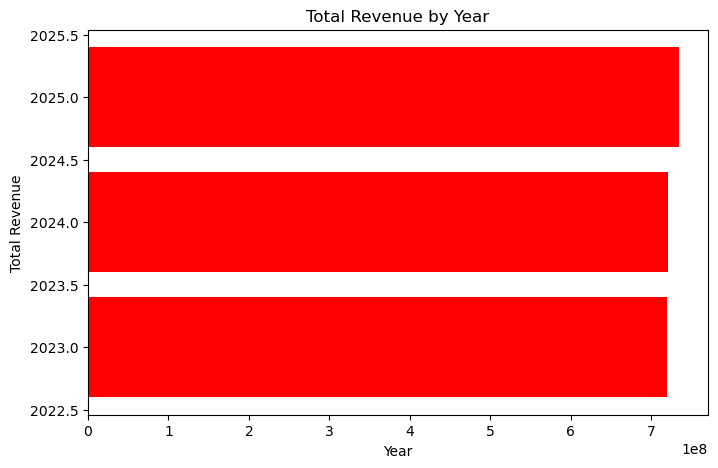

In [13]:
import matplotlib.pyplot as plt
yearly_revenue = df.groupby('year')['revenue'].sum()
plt.figure(figsize=(8,5))
plt.barh(yearly_revenue.index, yearly_revenue.values,color="red",height=0.8)
plt.xlabel('Year')
plt.ylabel('Total Revenue')
plt.title('Total Revenue by Year')
plt.show()

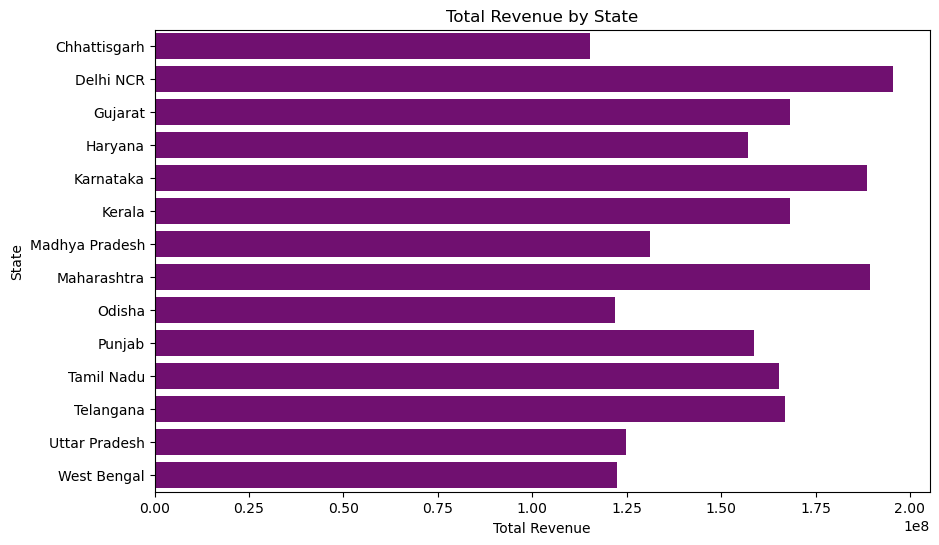

In [14]:
# Revenue by State.
import seaborn as sns
import matplotlib.pyplot as plt
state_revenue = df.groupby('state', as_index=False)['revenue'].sum()
plt.figure(figsize=(10,6))
sns.barplot(data=state_revenue, x='revenue', y='state',color='purple')
plt.title("Total Revenue by State")
plt.xlabel("Total Revenue")
plt.ylabel("State")
plt.show()

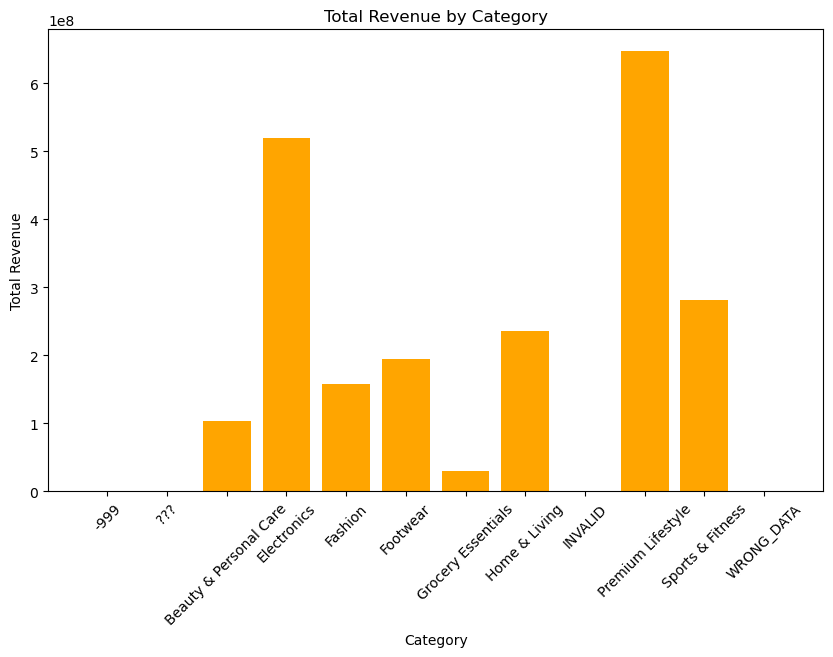

In [26]:
# Revenue by category 
reve_by_cat = df.groupby('category', as_index=False)['revenue'].sum()
plt.figure(figsize=(10, 6))
plt.bar(reve_by_cat['category'], reve_by_cat['revenue'], color='orange')
plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

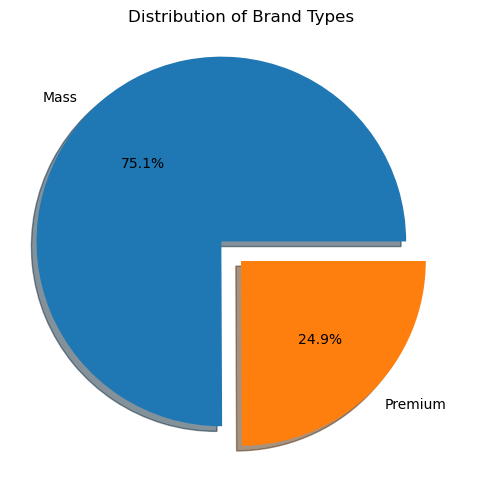

In [31]:
# Distribution of Brand Types
brand_counts = df['brand_type'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(brand_counts, labels=["Mass", "Premium"], explode=[0.15, 0], autopct='%1.1f%%', shadow=True)
plt.title("Distribution of Brand Types")
plt.show()

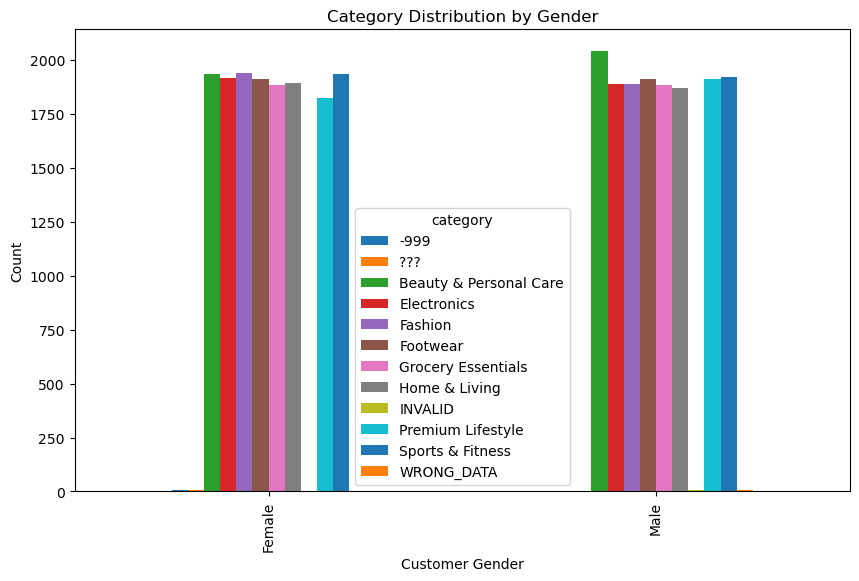

In [41]:
gender_category = df.groupby(['customer_gender', 'category']).size().unstack(fill_value=0)
gender_category.plot(kind='bar', figsize=(10,6))
plt.title("Category Distribution by Gender")
plt.xlabel("Customer Gender")
plt.ylabel("Count")
plt.show()